# Khảo sát dữ liệu sửa lỗi: VSEC, ViLexNorm, VEC

Độ dài câu, tỉ lệ câu có lỗi, số chỗ sửa mỗi câu và phân bố kiểu lỗi trên dữ liệu đã tiền xử lý (`data/processed/<tên>/{train,val,test}.jsonl`). Hình lưu ở `reports/figures/01_*.png`.

In [1]:
import os, sys, json
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, ".")
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG, TAB = Path("reports/figures"), Path("reports/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
COLORS = {"vsec": "#4C72B0", "vilexnorm": "#DD8452", "vec": "#55A868", "visp": "#8172B3"}
from src.utils.metrics import tokenize, word_edits
from src.data.augment_errors import strip_diacritics

NAMES = ["vsec", "vilexnorm", "vec"]
dfs = {n: pd.concat([pd.read_json(f"data/processed/{n}/{s}.jsonl", lines=True).assign(split=s)
                     for s in ["train", "val", "test"]], ignore_index=True) for n in NAMES}

## Số câu theo tập

In [2]:
sizes = pd.DataFrame({n: d.split.value_counts() for n, d in dfs.items()}).T[["train", "val", "test"]]
sizes["tổng"] = sizes.sum(axis=1)
sizes.to_csv(TAB / "01_dataset_sizes.csv")
sizes

split,train,val,test,tổng
vsec,7473,934,934,9341
vilexnorm,8370,1047,1041,10458
vec,49454,6079,6058,61591


## Độ dài câu (số từ của câu nguồn)

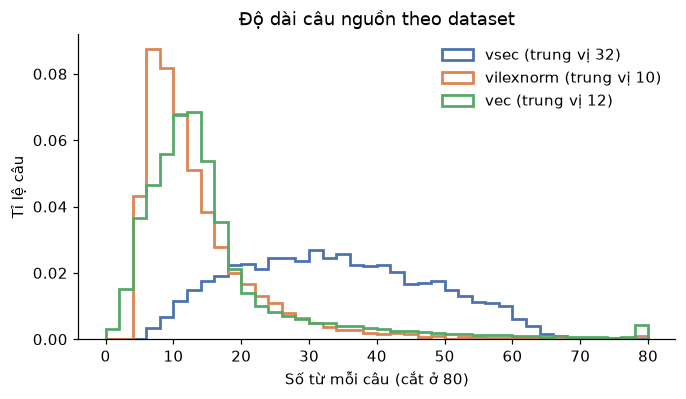

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for n, d in dfs.items():
    lens = d.source.map(lambda s: len(tokenize(s))).clip(upper=80)
    ax.hist(lens, bins=40, range=(0, 80), density=True, histtype="step", lw=1.8, color=COLORS[n],
            label=f"{n} (trung vị {int(lens.median())})")
ax.set(xlabel="Số từ mỗi câu (cắt ở 80)", ylabel="Tỉ lệ câu", title="Độ dài câu nguồn theo dataset")
ax.legend(frameon=False)
fig.savefig(FIG / "01_length_correction.png")

Tin nhắn MXH (ViLexNorm) ngắn hơn hẳn văn bản học thuật (VSEC), nên tập test chính của đồ án là ViLexNorm.

## Kiểu lỗi

Mỗi chỗ sửa (so câu nguồn với câu chuẩn bằng `word_edits`) được gán một nhãn theo quy tắc:
- **thiếu/sai dấu**: bỏ dấu hai bên thì giống nhau (`dc`→`dc` không tính, `di hoc`→`đi học` có tính);
- **viết tắt/teencode**: câu chuẩn dài hơn câu nguồn ít nhất 2 ký tự (`ko`→`không`, `ng`→`người`);
- **chữ hoa**: chỉ khác chữ hoa/thường; **dấu câu/khoảng trắng**: chỉ khác ở ký tự không phải chữ;
- **khác (gõ sai, thay từ)**: còn lại.

In [4]:
import re

def edit_type(src, tgt):
    if src.lower() == tgt.lower():
        return "chữ hoa"
    if re.sub(r"\W", "", src) == re.sub(r"\W", "", tgt):
        return "dấu câu/khoảng trắng"
    if strip_diacritics(src).lower() == strip_diacritics(tgt).lower():
        return "thiếu/sai dấu"
    if len(tgt.replace(" ", "")) >= len(src.replace(" ", "")) + 2:
        return "viết tắt/teencode"
    return "khác (gõ sai, thay từ)"

rows = []
for n, d in dfs.items():
    sample = d.sample(min(len(d), 8000), random_state=0)
    for s, t in zip(sample.source, sample.target):
        toks = tokenize(s)
        edits = word_edits(s, t)
        rows.append({"dataset": n, "has_error": bool(edits), "n_edits": len(edits),
                     "types": [edit_type(" ".join(toks[a:b]), " ".join(r)) for a, b, r in edits]})
edits_df = pd.DataFrame(rows)
summary = edits_df.groupby("dataset", sort=False).agg(ti_le_cau_co_loi=("has_error", "mean"),
                                                       so_cho_sua_tb=("n_edits", "mean"))
summary.to_csv(TAB / "01_error_rate.csv")
summary.style.format({"ti_le_cau_co_loi": "{:.1%}", "so_cho_sua_tb": "{:.2f}"})

,ti_le_cau_co_loi,so_cho_sua_tb
dataset,,
vsec,100.0%,1.16
vilexnorm,100.0%,1.65
vec,82.2%,2.41


types,thiếu/sai dấu,viết tắt/teencode,"khác (gõ sai, thay từ)",chữ hoa,dấu câu/khoảng trắng
dataset,,,,,
vsec,64.9%,1.2%,31.5%,0.0%,2.4%
vilexnorm,3.7%,60.1%,35.8%,0.1%,0.3%
vec,48.1%,11.6%,36.4%,2.9%,1.1%


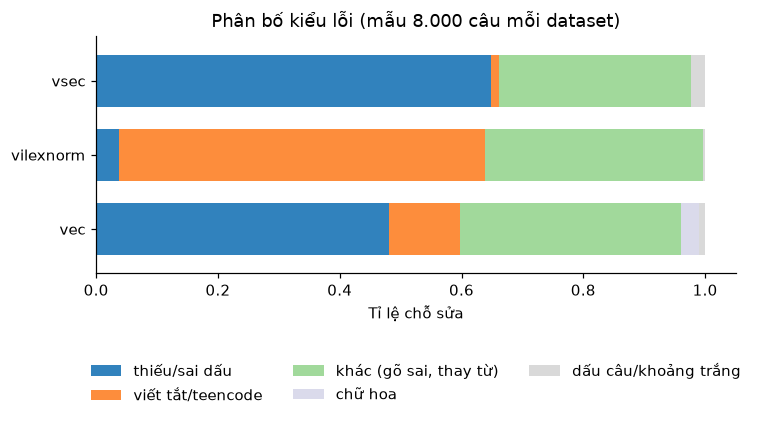

In [5]:
types = edits_df.explode("types").dropna(subset=["types"]).reset_index(drop=True)
dist = pd.crosstab(types.dataset, types.types, normalize="index").loc[NAMES]
order = ["thiếu/sai dấu", "viết tắt/teencode", "khác (gõ sai, thay từ)", "chữ hoa", "dấu câu/khoảng trắng"]
dist = dist[[c for c in order if c in dist]]
dist.to_csv(TAB / "01_edit_types.csv")
ax = dist.plot.barh(stacked=True, figsize=(7.5, 2.8), colormap="tab20c", width=0.7)
ax.set(xlabel="Tỉ lệ chỗ sửa", ylabel="", title="Phân bố kiểu lỗi (mẫu 8.000 câu mỗi dataset)")
ax.legend(ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.32), loc="upper center")
ax.invert_yaxis()
ax.figure.savefig(FIG / "01_edit_types.png")
dist.style.format("{:.1%}")

## Dữ liệu lỗi nhân tạo (chỉ thêm vào train)

Phân bố hồ sơ lỗi trong `correction/train_aug.jsonl` (dòng có `profile` = câu do `augment_errors` sinh ra).

154,487 câu train, trong đó 89,190 câu lỗi nhân tạo


,số câu
profile,
fast_typing,66592
single,22598


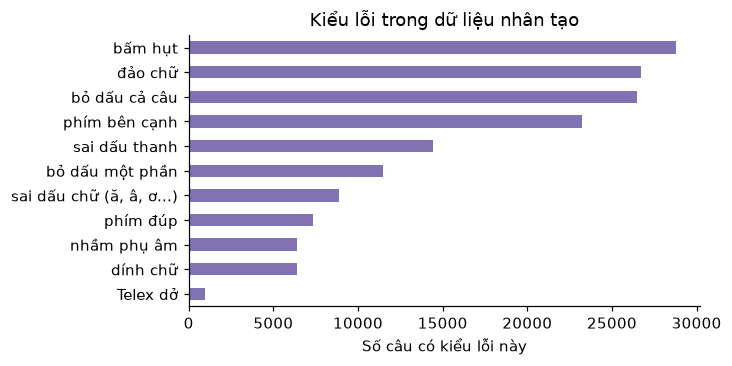

In [6]:
aug = pd.read_json("data/processed/correction/train_aug.jsonl", lines=True)
synthetic = aug[aug.profile.notna()]
print(f"{len(aug):,} câu train, trong đó {len(synthetic):,} câu lỗi nhân tạo")
VI = {"delete": "bấm hụt", "transpose": "đảo chữ", "strip_full": "bỏ dấu cả câu", "keyboard": "phím bên cạnh",
      "tone": "sai dấu thanh", "strip_partial": "bỏ dấu một phần", "vowel_mark": "sai dấu chữ (ă, â, ơ...)",
      "double": "phím đúp", "consonant": "nhầm phụ âm", "merge": "dính chữ", "telex": "Telex dở"}
et = synthetic.error_types.explode().value_counts().rename(index=lambda k: VI.get(k, k))
ax = et.sort_values().plot.barh(figsize=(6, 3.2), color="#8172B3")
ax.set(xlabel="Số câu có kiểu lỗi này", ylabel="", title="Kiểu lỗi trong dữ liệu nhân tạo")
ax.figure.savefig(FIG / "01_augment_types.png")
synthetic.profile.value_counts().to_frame("số câu")